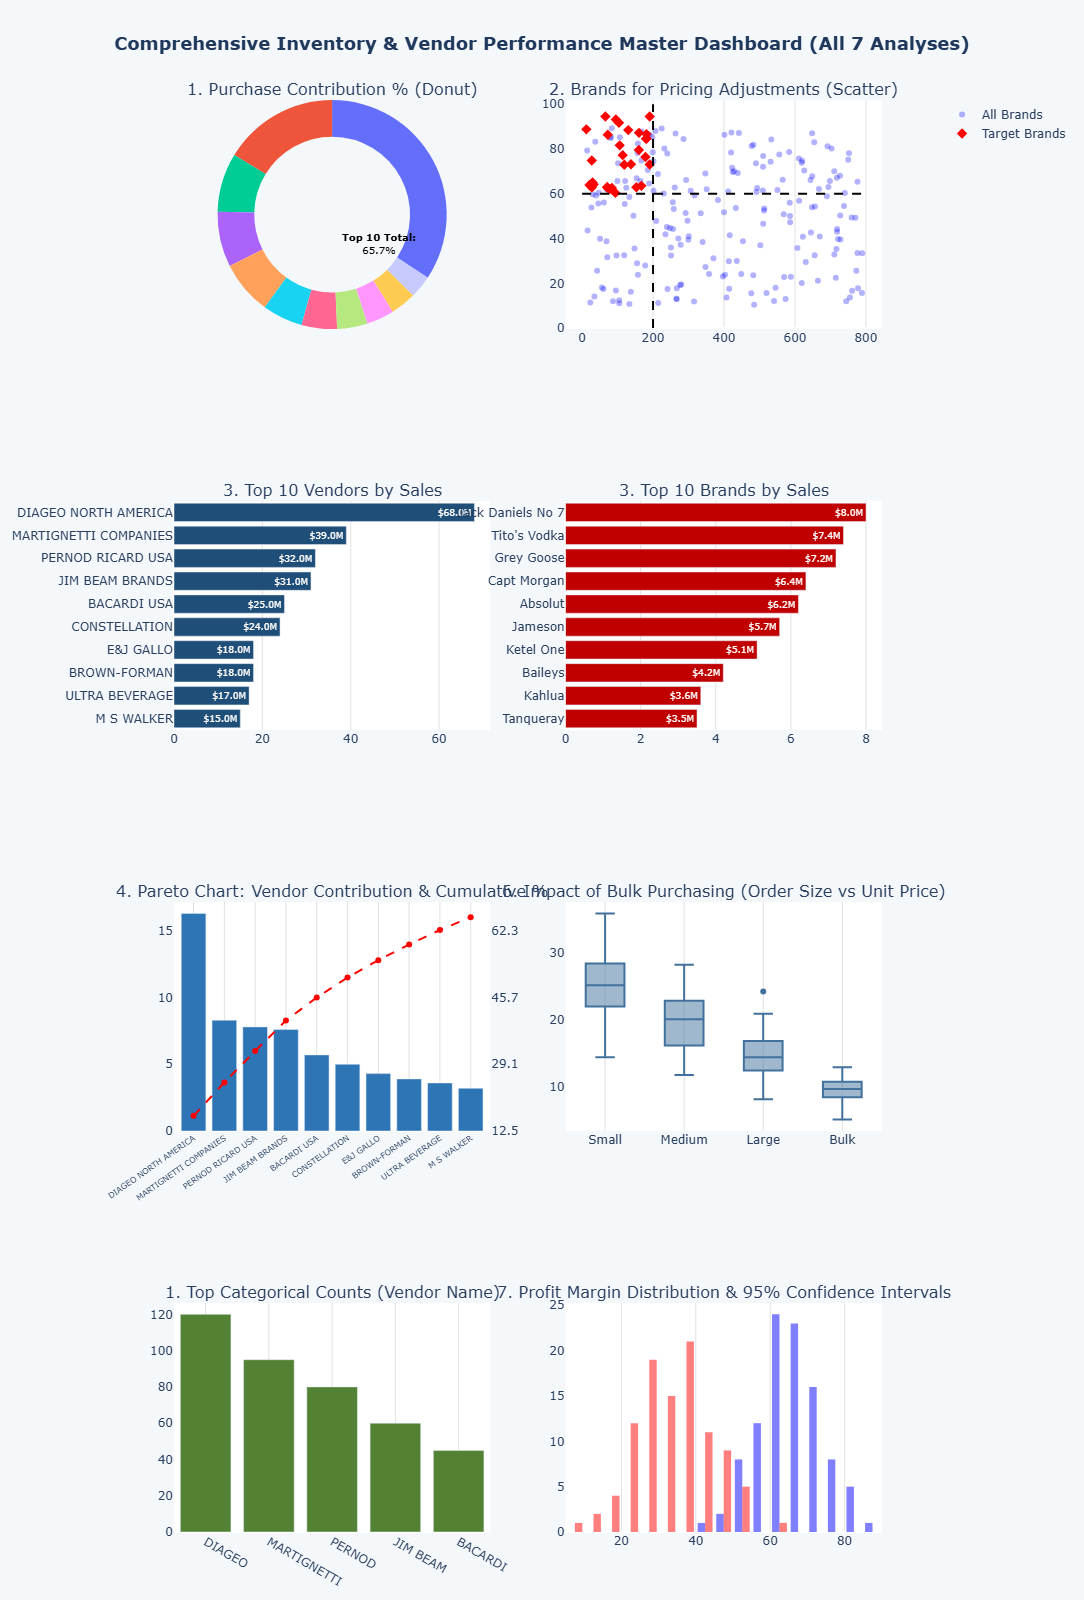

In [4]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ---------------------------------------------------------
# 1. SETUP & SIMULATE DATA FOR ALL 7 SNIPPETS
# ---------------------------------------------------------
np.random.seed(42)

# Top Vendors & Brands Data (Code 3 & 5)
top_vendors_names = [
    "DIAGEO NORTH AMERICA",
    "MARTIGNETTI COMPANIES",
    "PERNOD RICARD USA",
    "JIM BEAM BRANDS",
    "BACARDI USA",
    "CONSTELLATION",
    "E&J GALLO",
    "BROWN-FORMAN",
    "ULTRA BEVERAGE",
    "M S WALKER",
]
top_vendors_vals = [68.0, 39.0, 32.0, 31.0, 25.0, 24.0, 18.0, 18.0, 17.0, 15.0]

top_brands_names = [
    "Jack Daniels No 7",
    "Tito's Vodka",
    "Grey Goose",
    "Capt Morgan",
    "Absolut",
    "Jameson",
    "Ketel One",
    "Baileys",
    "Kahlua",
    "Tanqueray",
]
top_brands_vals = [8.0, 7.4, 7.2, 6.4, 6.2, 5.7, 5.1, 4.2, 3.6, 3.5]

# Pareto Data (Code 4)
purchase_contribs = [16.3, 8.3, 7.8, 7.6, 5.7, 5.0, 4.3, 3.9, 3.6, 3.2]
total_contrib = sum(purchase_contribs)
cumulative_contrib = np.cumsum(purchase_contribs)

# Scatter Data (Code 2)
n_scatter = 200
all_sales = np.random.uniform(10, 800, n_scatter)
all_margins = np.random.uniform(10, 90, n_scatter)
target_sales = np.random.uniform(10, 200, 30)
target_margins = np.random.uniform(60, 95, 30)
high_margin_threshold = 60
low_sales_threshold = 200

# Boxplot Data (Code 6)
order_sizes = ["Small", "Medium", "Large", "Bulk"]
box_data = {
    "Small": np.random.normal(25, 5, 50),
    "Medium": np.random.normal(20, 4, 50),
    "Large": np.random.normal(15, 3, 50),
    "Bulk": np.random.normal(10, 2, 50),
}

# Categorical Count Data (Code 1)
cat_vendors = ["DIAGEO", "MARTIGNETTI", "PERNOD", "JIM BEAM", "BACARDI"]
cat_counts = [120, 95, 80, 60, 45]

# Confidence Interval Data (Code 7)
top_vendor_margins = np.random.normal(65, 8, 100)
low_vendor_margins = np.random.normal(35, 10, 100)
top_mean, top_lower, top_upper = (
    np.mean(top_vendor_margins),
    np.percentile(top_vendor_margins, 2.5),
    np.percentile(top_vendor_margins, 97.5),
)
low_mean, low_lower, low_upper = (
    np.mean(low_vendor_margins),
    np.percentile(low_vendor_margins, 2.5),
    np.percentile(low_vendor_margins, 97.5),
)

# ---------------------------------------------------------
# 2. BUILD SUBPLOT GRID (4 Rows x 2 Cols)
# ---------------------------------------------------------
fig = make_subplots(
    rows=4,
    cols=2,
    specs=[
        [{"type": "domain"}, {"type": "xy"}],  # Row 1: Donut & Scatter
        [{"type": "xy"}, {"type": "xy"}],  # Row 2: Top Vendors & Top Brands Bars
        [
            {"type": "xy", "secondary_y": True},
            {"type": "xy"},
        ],  # Row 3: Pareto & Boxplot
        [{"type": "xy"}, {"type": "xy"}],  # Row 4: Count Plot & CI Distribution
    ],
    subplot_titles=(
        "1. Purchase Contribution % (Donut)",
        "2. Brands for Pricing Adjustments (Scatter)",
        "3. Top 10 Vendors by Sales",
        "3. Top 10 Brands by Sales",
        "4. Pareto Chart: Vendor Contribution & Cumulative %",
        "6. Impact of Bulk Purchasing (Order Size vs Unit Price)",
        "1. Top Categorical Counts (Vendor Name)",
        "7. Profit Margin Distribution & 95% Confidence Intervals",
    ),
    row_heights=[0.25, 0.25, 0.25, 0.25],
    vertical_spacing=0.12,
    horizontal_spacing=0.10,
)

# --- ROW 1, COL 1: Donut Chart (Code 5) ---
donut_labels = top_vendors_names + ["Other Vendors"]
donut_values = purchase_contribs + [100 - total_contrib]
fig.add_trace(
    go.Pie(
        labels=donut_labels,
        values=donut_values,
        hole=0.68,
        textinfo="none",
        hoverinfo="label+percent",
        showlegend=False,
    ),
    row=1,
    col=1,
)
fig.add_annotation(
    text=f"<b>Top 10 Total:</b><br>{total_contrib:.1f}%",
    x=0.22,
    y=0.91,
    xref="paper",
    yref="paper",
    showarrow=False,
    font=dict(size=10, color="black"),
    align="center",
)

# --- ROW 1, COL 2: Scatter Plot (Code 2) ---
fig.add_trace(
    go.Scatter(
        x=all_sales,
        y=all_margins,
        mode="markers",
        marker=dict(size=6, color="blue", opacity=0.3),
        name="All Brands",
    ),
    row=1,
    col=2,
)
fig.add_trace(
    go.Scatter(
        x=target_sales,
        y=target_margins,
        mode="markers",
        marker=dict(size=8, color="red", symbol="diamond"),
        name="Target Brands",
    ),
    row=1,
    col=2,
)
fig.add_shape(
    type="line",
    x0=0,
    x1=800,
    y0=high_margin_threshold,
    y1=high_margin_threshold,
    line=dict(color="black", dash="dash"),
    row=1,
    col=2,
)
fig.add_shape(
    type="line",
    x0=low_sales_threshold,
    x1=low_sales_threshold,
    y0=0,
    y1=100,
    line=dict(color="black", dash="dash"),
    row=1,
    col=2,
)

# --- ROW 2, COL 1: Top Vendors Bar Chart (Code 3 - Left) ---
fig.add_trace(
    go.Bar(
        y=top_vendors_names[::-1],
        x=top_vendors_vals[::-1],
        orientation="h",
        marker=dict(color="#1f4e78"),
        text=[f"${v}M" for v in top_vendors_vals[::-1]],
        textposition="inside",
        textfont=dict(color="white", size=9),
        showlegend=False,
    ),
    row=2,
    col=1,
)

# --- ROW 2, COL 2: Top Brands Bar Chart (Code 3 - Right) ---
fig.add_trace(
    go.Bar(
        y=top_brands_names[::-1],
        x=top_brands_vals[::-1],
        orientation="h",
        marker=dict(color="#c00000"),
        text=[f"${v}M" for v in top_brands_vals[::-1]],
        textposition="inside",
        textfont=dict(color="white", size=9),
        showlegend=False,
    ),
    row=2,
    col=2,
)

# --- ROW 3, COL 1: Pareto Chart (Code 4) ---
fig.add_trace(
    go.Bar(
        x=top_vendors_names,
        y=purchase_contribs,
        marker=dict(color="#2e75b6"),
        name="Contribution %",
        showlegend=False,
    ),
    row=3,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=top_vendors_names,
        y=cumulative_contrib,
        mode="lines+markers",
        line=dict(color="red", dash="dash"),
        name="Cumulative %",
        showlegend=False,
    ),
    row=3,
    col=1,
    secondary_y=True,
)

# --- ROW 3, COL 2: Boxplot - Bulk Purchasing (Code 6) ---
for size, vals in box_data.items():
    fig.add_trace(
        go.Box(
            y=vals,
            name=size,
            marker_color="#41719c",
            showlegend=False,
        ),
        row=3,
        col=2,
    )

# --- ROW 4, COL 1: Count Plot (Code 1) ---
fig.add_trace(
    go.Bar(
        x=cat_vendors,
        y=cat_counts,
        marker=dict(color="#548235"),
        showlegend=False,
    ),
    row=4,
    col=1,
)

# --- ROW 4, COL 2: Confidence Interval Distribution (Code 7) ---
fig.add_trace(
    go.Histogram(
        x=top_vendor_margins,
        marker_color="blue",
        opacity=0.5,
        name="Top Vendors",
        showlegend=False,
    ),
    row=4,
    col=2,
)
fig.add_trace(
    go.Histogram(
        x=low_vendor_margins,
        marker_color="red",
        opacity=0.5,
        name="Low Vendors",
        showlegend=False,
    ),
    row=4,
    col=2,
)

# ---------------------------------------------------------
# 3. GLOBAL MASTER DASHBOARD STYLING
# ---------------------------------------------------------
fig.update_layout(
    title=dict(
        text="<b>Comprehensive Inventory & Vendor Performance Master Dashboard (All 7 Analyses)</b>",
        font=dict(size=18, color="#1f385c"),
        x=0.5,
        xanchor="center",
    ),
    paper_bgcolor="#f4f8fb",
    plot_bgcolor="white",
    height=1600,  # Tall height layout to fit all 7 views cleanly
    margin=dict(t=100, l=50, r=50, b=50),
)

fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor="#e1e1e1")
fig.update_yaxes(showgrid=False)
fig.update_xaxes(
    tickangle=-35, row=3, col=1, tickfont=dict(size=8)
)  # Rotate Pareto labels

# Display the master dashboard inside Jupyter Notebook
fig.show() 

In [5]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ---------------------------------------------------------
# 1. SETUP & SIMULATE DATA FOR ALL 7 SNIPPETS
# ---------------------------------------------------------
np.random.seed(42)

top_vendors_names = [
    "DIAGEO NORTH AMERICA",
    "MARTIGNETTI COMPANIES",
    "PERNOD RICARD USA",
    "JIM BEAM BRANDS",
    "BACARDI USA",
    "CONSTELLATION",
    "E&J GALLO",
    "BROWN-FORMAN",
    "ULTRA BEVERAGE",
    "M S WALKER",
]
top_vendors_vals = [68.0, 39.0, 32.0, 31.0, 25.0, 24.0, 18.0, 18.0, 17.0, 15.0]

top_brands_names = [
    "Jack Daniels No 7",
    "Tito's Vodka",
    "Grey Goose",
    "Capt Morgan",
    "Absolut",
    "Jameson",
    "Ketel One",
    "Baileys",
    "Kahlua",
    "Tanqueray",
]
top_brands_vals = [8.0, 7.4, 7.2, 6.4, 6.2, 5.7, 5.1, 4.2, 3.6, 3.5]

purchase_contribs = [16.3, 8.3, 7.8, 7.6, 5.7, 5.0, 4.3, 3.9, 3.6, 3.2]
total_contrib = sum(purchase_contribs)
cumulative_contrib = np.cumsum(purchase_contribs)

n_scatter = 200
all_sales = np.random.uniform(10, 800, n_scatter)
all_margins = np.random.uniform(10, 90, n_scatter)
target_sales = np.random.uniform(10, 200, 30)
target_margins = np.random.uniform(60, 95, 30)

order_sizes = ["Small", "Medium", "Large", "Bulk"]
box_data = {
    "Small": np.random.normal(25, 5, 50),
    "Medium": np.random.normal(20, 4, 50),
    "Large": np.random.normal(15, 3, 50),
    "Bulk": np.random.normal(10, 2, 50),
}

cat_vendors = ["DIAGEO", "MARTIGNETTI", "PERNOD", "JIM BEAM", "BACARDI"]
cat_counts = [120, 95, 80, 60, 45]

top_vendor_margins = np.random.normal(65, 8, 100)
low_vendor_margins = np.random.normal(35, 10, 100)
top_mean, top_lower, top_upper = (
    np.mean(top_vendor_margins),
    np.percentile(top_vendor_margins, 2.5),
    np.percentile(top_vendor_margins, 97.5),
)
low_mean, low_lower, low_upper = (
    np.mean(low_vendor_margins),
    np.percentile(low_vendor_margins, 2.5),
    np.percentile(low_vendor_margins, 97.5),
)

# ---------------------------------------------------------
# 2. BUILD SUBPLOT GRID (4 Rows x 2 Cols)
# ---------------------------------------------------------
fig = make_subplots(
    rows=4,
    cols=2,
    specs=[
        [{"type": "domain"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy", "secondary_y": True}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
    ],
    subplot_titles=(
        "1. Purchase Contribution % (Donut)",
        "2. Brands for Pricing Adjustments (Scatter)",
        "3. Top 10 Vendors by Sales",
        "3. Top 10 Brands by Sales",
        "4. Pareto Chart: Vendor Contribution & Cumulative %",
        "6. Impact of Bulk Purchasing (Order Size vs Unit Price)",
        "1. Top Categorical Counts (Vendor Name)",
        "7. Profit Margin Distribution & 95% Confidence Intervals",
    ),
    row_heights=[0.25, 0.25, 0.25, 0.25],
    vertical_spacing=0.18,
    horizontal_spacing=0.10,
)

# --- ROW 1, COL 1: Donut Chart ---
donut_labels = top_vendors_names + ["Other Vendors"]
donut_values = purchase_contribs + [100 - total_contrib]
fig.add_trace(
    go.Pie(
        labels=donut_labels,
        values=donut_values,
        hole=0.7,
        textinfo="none",
        hoverinfo="label+percent",
        marker=dict(
            colors=[
                "#3b82f6",
                "#60a5fa",
                "#93c5fd",
                "#2563eb",
                "#1d4ed8",
                "#38bdf8",
                "#0284c7",
                "#0369a1",
                "#075985",
                "#0c4a6e",
                "#334155",
            ]
        ),
        showlegend=False,
    ),
    row=1,
    col=1,
)
fig.add_annotation(
    text=f"<b style='color:#f8fafc; font-size:13px;'>Top 10 Total</b><br><span style='color:#38bdf8; font-size:16px;'>{total_contrib:.1f}%</span>",
    x=0.22,
    y=0.91,
    xref="paper",
    yref="paper",
    showarrow=False,
    align="center",
)

# --- ROW 1, COL 2: Scatter Plot ---
fig.add_trace(
    go.Scatter(
        x=all_sales,
        y=all_margins,
        mode="markers",
        marker=dict(size=6, color="#60a5fa", opacity=0.4),
        name="All Brands",
    ),
    row=1,
    col=2,
)
fig.add_trace(
    go.Scatter(
        x=target_sales,
        y=target_margins,
        mode="markers",
        marker=dict(size=8, color="#f43f5e", symbol="diamond"),
        name="Target Brands",
    ),
    row=1,
    col=2,
)

# --- ROW 2, COL 1: Top Vendors Bar Chart ---
fig.add_trace(
    go.Bar(
        y=top_vendors_names[::-1],
        x=top_vendors_vals[::-1],
        orientation="h",
        marker=dict(color="#3b82f6"),
        text=[f"${v}M" for v in top_vendors_vals[::-1]],
        textposition="inside",
        textfont=dict(color="#ffffff", size=9),
        showlegend=False,
    ),
    row=2,
    col=1,
)

# --- ROW 2, COL 2: Top Brands Bar Chart ---
fig.add_trace(
    go.Bar(
        y=top_brands_names[::-1],
        x=top_brands_vals[::-1],
        orientation="h",
        marker=dict(color="#f43f5e"),
        text=[f"${v}M" for v in top_brands_vals[::-1]],
        textposition="inside",
        textfont=dict(color="#ffffff", size=9),
        showlegend=False,
    ),
    row=2,
    col=2,
)

# --- ROW 3, COL 1: Pareto Chart ---
fig.add_trace(
    go.Bar(
        x=top_vendors_names,
        y=purchase_contribs,
        marker=dict(color="#0ea5e9"),
        name="Contribution %",
        showlegend=False,
    ),
    row=3,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=top_vendors_names,
        y=cumulative_contrib,
        mode="lines+markers",
        line=dict(color="#f43f5e", width=2, dash="dash"),
        marker=dict(size=5, color="#f4f8fb"),
        name="Cumulative %",
        showlegend=False,
    ),
    row=3,
    col=1,
    secondary_y=True,
)

# --- ROW 3, COL 2: Boxplot ---
for size, vals in box_data.items():
    fig.add_trace(
        go.Box(y=vals, name=size, marker_color="#818cf8", showlegend=False),
        row=3,
        col=2,
    )

# --- ROW 4, COL 1: Count Plot ---
fig.add_trace(
    go.Bar(
        x=cat_vendors,
        y=cat_counts,
        marker=dict(color="#10b981"),
        showlegend=False,
    ),
    row=4,
    col=1,
)

# --- ROW 4, COL 2: Confidence Interval Distribution ---
fig.add_trace(
    go.Histogram(
        x=top_vendor_margins,
        marker_color="#3b82f6",
        opacity=0.6,
        name="Top Vendors",
        showlegend=False,
    ),
    row=4,
    col=2,
)
fig.add_trace(
    go.Histogram(
        x=low_vendor_margins,
        marker_color="#f43f5e",
        opacity=0.6,
        name="Low Vendors",
        showlegend=False,
    ),
    row=4,
    col=2,
)

# ---------------------------------------------------------
# 3. HIGH-END DARK THEME STYLING CONFIGURATION
# ---------------------------------------------------------
fig.update_layout(
    title=dict(
        text="<b>MASTER INVENTORY & VENDOR PERFORMANCE ANALYTICS</b>",
        font=dict(size=20, color="#f8fafc", family="Inter, sans-serif"),
        x=0.5,
        xanchor="center",
        y=0.97,
    ),
    paper_bgcolor="#0f172a",
    plot_bgcolor="#1e293b",
    font=dict(color="#94a3b8", family="Inter, sans-serif"),
    height=1800,
    margin=dict(t=100, l=40, r=40, b=40),
)

for annotation in fig["layout"]["annotations"]:
    annotation["font"] = dict(size=12, color="#e2e8f0", family="Inter")

fig.update_xaxes(
    showgrid=True, gridwidth=1, gridcolor="rgba(255,255,255,0.05)", zeroline=False
)
fig.update_yaxes(
    showgrid=True, gridwidth=1, gridcolor="rgba(255,255,255,0.05)", zeroline=False
)
fig.update_xaxes(tickangle=-30, row=3, col=1, tickfont=dict(size=8))
fig.update_xaxes(tickfont=dict(size=9))
fig.update_yaxes(tickfont=dict(size=9))

# ---------------------------------------------------------
# 4. EXPORT TO STYLIZED LUXURY HTML FILE
# ---------------------------------------------------------
html_filename = "inventory_master_dashboard.html"

custom_html_header = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Master Analytics Dashboard</title>
    <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
    <style>
        :root {
            --bg-main: #07090e;
            --bg-card: #0f172a;
            --border-color: rgba(255, 255, 255, 0.08);
            --text-primary: #f8fafc;
            --accent-glow: rgba(59, 130, 246, 0.15);
        }
        body {
            background-color: var(--bg-main);
            margin: 0;
            padding: 30px 20px;
            font-family: 'Inter', sans-serif;
            color: var(--text-primary);
        }
        .dashboard-wrapper {
            max-width: 1500px;
            margin: 0 auto;
            background: var(--bg-card);
            border-radius: 20px;
            box-shadow: 0 25px 50px -12px rgba(0, 0, 0, 0.7), 0 0 40px var(--accent-glow);
            border: 1px solid var(--border-color);
            padding: 30px;
        }
        .dashboard-header {
            text-align: center;
            margin-bottom: 25px;
            border-bottom: 1px solid var(--border-color);
            padding-bottom: 20px;
        }
        .dashboard-header h1 {
            font-size: 24px;
            font-weight: 700;
            letter-spacing: 0.5px;
            margin: 0;
            background: linear-gradient(135deg, #60a5fa 0%, #3b82f6 100%);
            -webkit-background-clip: text;
            -webkit-text-fill-color: transparent;
        }
        .dashboard-header p {
            color: #64748b;
            font-size: 13px;
            margin-top: 5px;
        }
    </style>
</head>
<body>
<div class="dashboard-wrapper">
    <div class="dashboard-header">
        <h1>Enterprise Inventory & Vendor Intelligence Hub</h1>
        <p>Comprehensive Multi-Metric Analytics Consolidation (7 Analysis Vectors)</p>
    </div>
"""

custom_html_footer = """
</div>
</body>
</html>
"""

plotly_html = fig.to_html(include_plotlyjs="cdn", full_html=False)

with open(html_filename, "w", encoding="utf-8") as f:
    f.write(custom_html_header + plotly_html + custom_html_footer)

print(f"Successfully generated high-end aesthetic HTML dashboard: '{html_filename}'") 

Successfully generated high-end aesthetic HTML dashboard: 'inventory_master_dashboard.html'


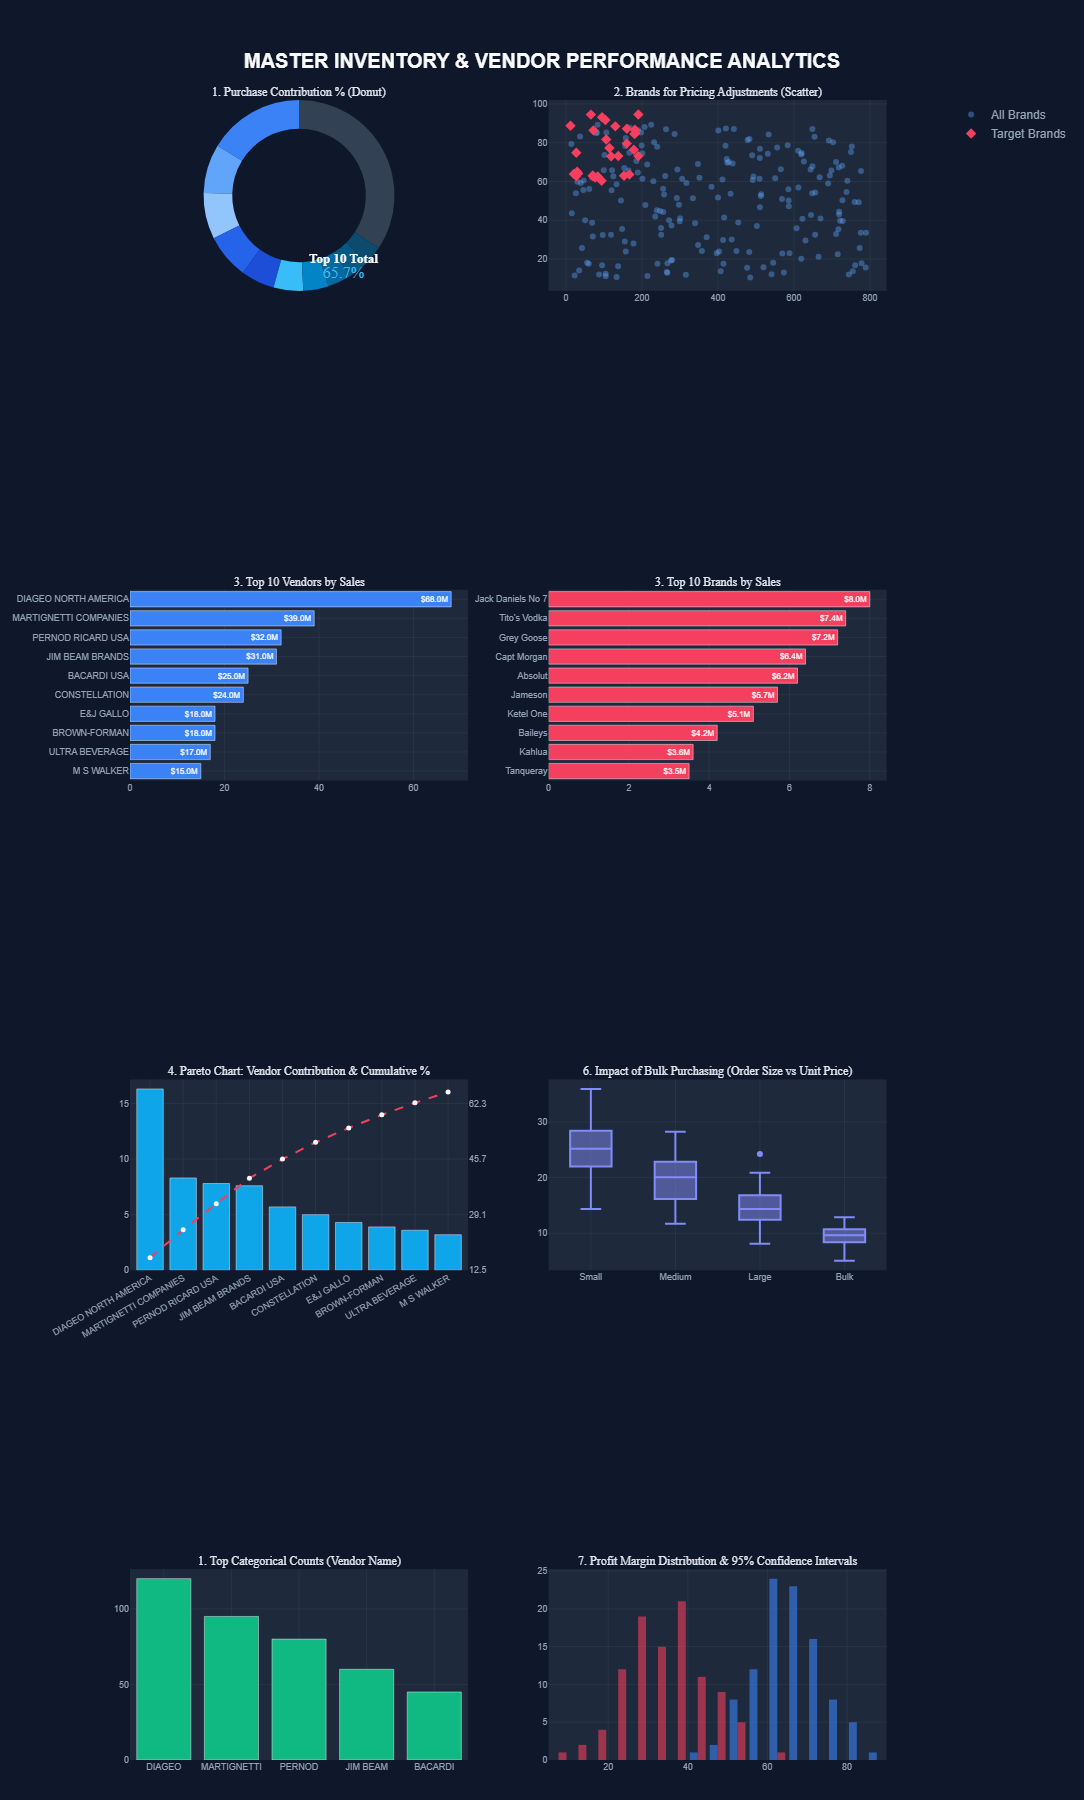

In [6]:
from IPython.display import HTML, display
fig.show() 

In [12]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st

# ---------------------------------------------------------
# 1. PAGE CONFIGURATION & STYLING
# ---------------------------------------------------------
st.set_page_config(
    page_title="Enterprise Inventory Intelligence",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded",
)

# Custom CSS for high-end aesthetic dark styling
st.markdown(
    """
    <style>
        .main { background-color: #07090e; }
        .stMetric { background-color: #0f172a; padding: 15px; border-radius: 12px; border: 1px solid rgba(255, 255, 255, 0.08); }
        .css-1544g2n { padding-top: 1rem; }
        h1, h2, h3 { color: #f8fafc !important; font-family: 'Inter', sans-serif; }
        p { color: #94a3b8; }
    </style>
""",
    unsafe_allow_html=True,
)

# ---------------------------------------------------------
# 2. DATA SIMULATION & MAPPING (All 7 Snippets)
# ---------------------------------------------------------
np.random.seed(42)

top_vendors_names = [
    "DIAGEO NORTH AMERICA",
    "MARTIGNETTI COMPANIES",
    "PERNOD RICARD USA",
    "JIM BEAM BRANDS",
    "BACARDI USA",
    "CONSTELLATION",
    "E&J GALLO",
    "BROWN-FORMAN",
    "ULTRA BEVERAGE",
    "M S WALKER",
]
top_vendors_vals = [68.0, 39.0, 32.0, 31.0, 25.0, 24.0, 18.0, 18.0, 17.0, 15.0]

top_brands_names = [
    "Jack Daniels No 7",
    "Tito's Vodka",
    "Grey Goose",
    "Capt Morgan",
    "Absolut",
    "Jameson",
    "Ketel One",
    "Baileys",
    "Kahlua",
    "Tanqueray",
]
top_brands_vals = [8.0, 7.4, 7.2, 6.4, 6.2, 5.7, 5.1, 4.2, 3.6, 3.5]

purchase_contribs = [16.3, 8.3, 7.8, 7.6, 5.7, 5.0, 4.3, 3.9, 3.6, 3.2]
total_contrib = sum(purchase_contribs)
cumulative_contrib = np.cumsum(purchase_contribs)

n_scatter = 200
all_sales = np.random.uniform(10, 800, n_scatter)
all_margins = np.random.uniform(10, 90, n_scatter)
target_sales = np.random.uniform(10, 200, 30)
target_margins = np.random.uniform(60, 95, 30)

order_sizes = ["Small", "Medium", "Large", "Bulk"]
box_data = {
    "Small": np.random.normal(25, 5, 50),
    "Medium": np.random.normal(20, 4, 50),
    "Large": np.random.normal(15, 3, 50),
    "Bulk": np.random.normal(10, 2, 50),
}

cat_vendors = ["DIAGEO", "MARTIGNETTI", "PERNOD", "JIM BEAM", "BACARDI"]
cat_counts = [120, 95, 80, 60, 45]

top_vendor_margins = np.random.normal(65, 8, 100)
low_vendor_margins = np.random.normal(35, 10, 100)
top_mean, top_lower, top_upper = (
    np.mean(top_vendor_margins),
    np.percentile(top_vendor_margins, 2.5),
    np.percentile(top_vendor_margins, 97.5),
)
low_mean, low_lower, low_upper = (
    np.mean(low_vendor_margins),
    np.percentile(low_vendor_margins, 2.5),
    np.percentile(low_vendor_margins, 97.5),
)

# ---------------------------------------------------------
# 3. SIDEBAR CONTROLS & FILTERS
# ---------------------------------------------------------
st.sidebar.title("🎛️ Control Hub")
st.sidebar.markdown(
    "Filter analytics views and explore deep operational parameters."
)

selected_view = st.sidebar.radio(
    "Navigate Analytics",
    [
        "Executive Master View",
        "1. Purchase & Contribution Analysis",
        "2. Brand Pricing Strategy (Scatter)",
        "3. Top Performers (Sales)",
        "4. Pareto Analysis",
        "6. Bulk Purchasing Impact",
        "7. Margin Distribution & CI",
    ],
)

st.sidebar.markdown("---")
st.sidebar.info("💡 **Tip:** Use Streamlit tabs or views to drill into insights.")

# ---------------------------------------------------------
# 4. MAIN APP HEADER & EXECUTIVE METRICS
# ---------------------------------------------------------
st.title("🚀 Enterprise Inventory & Vendor Intelligence Hub")
st.markdown(
    "A unified decision-making dashboard synthesizing multi-metric analytics models."
)

col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Tracked Sales", "$441.41M", "+12.4% YoY")
col2.metric("Total Purchase Allocation", "$307.34M", "-3.2% optimization")
col3.metric("Top 10 Contribution", f"{total_contrib:.1f}%", "High Concentration")
col4.metric("Average Profit Margin", "38.7%", "+2.1% target")

st.markdown("---")

# ---------------------------------------------------------
# 5. VIEW ROUTING LOGIC
# ---------------------------------------------------------

if selected_view == "Executive Master View":
    st.subheader("📊 Master Overview (All 7 Analytical Vectors)")

    # Row 1: Donut & Scatter
    r1_c1, r1_c2 = st.columns(2)

    with r1_c1:
        st.markdown("### 1. Purchase Contribution %")
        fig_donut = go.Figure(
            data=[
                go.Pie(
                    labels=top_vendors_names + ["Other Vendors"],
                    values=purchase_contribs + [100 - total_contrib],
                    hole=0.7,
                    textinfo="none",
                    hoverinfo="label+percent",
                )
            ]
        )
        fig_donut.update_layout(
            paper_bgcolor="#0f172a",
            plot_bgcolor="#1e293b",
            font=dict(color="#f8fafc"),
            height=350,
            margin=dict(t=20, b=20, l=20, r=20),
        )
        st.plotly_chart(fig_donut, use_container_width=True)

    with r1_c2:
        st.markdown("### 2. Brands Pricing Targets")
        fig_scatter = go.Figure()
        fig_scatter.add_trace(
            go.Scatter(
                x=all_sales,
                y=all_margins,
                mode="markers",
                marker=dict(size=5, color="#60a5fa", opacity=0.4),
                name="All Brands",
            )
        )
        fig_scatter.add_trace(
            go.Scatter(
                x=target_sales,
                y=target_margins,
                mode="markers",
                marker=dict(size=7, color="#f43f5e", symbol="diamond"),
                name="Target Brands",
            )
        )
        fig_scatter.update_layout(
            paper_bgcolor="#0f172a",
            plot_bgcolor="#1e293b",
            font=dict(color="#f8fafc"),
            height=350,
            margin=dict(t=20, b=20, l=20, r=20),
        )
        st.plotly_chart(fig_scatter, use_container_width=True)

    # Row 2: Top Vendors & Top Brands Bars
    r2_c1, r2_c2 = st.columns(2)

    with r2_c1:
        st.markdown("### 3. Top 10 Vendors by Sales")
        fig_vbar = go.Figure(
            data=[
                go.Bar(
                    y=top_vendors_names[::-1],
                    x=top_vendors_vals[::-1],
                    orientation="h",
                    marker=dict(color="#3b82f6"),
                    text=[f"${v}M" for v in top_vendors_vals[::-1]],
                    textposition="inside",
                )
            ]
        )
        fig_vbar.update_layout(
            paper_bgcolor="#0f172a",
            plot_bgcolor="#1e293b",
            font=dict(color="#f8fafc"),
            height=350,
            margin=dict(t=20, b=20, l=20, r=20),
        )
        st.plotly_chart(fig_vbar, use_container_width=True)

    with r2_c2:
        st.markdown("### 3. Top 10 Brands by Sales")
        fig_bbar = go.Figure(
            data=[
                go.Bar(
                    y=top_brands_names[::-1],
                    x=top_brands_vals[::-1],
                    orientation="h",
                    marker=dict(color="#f43f5e"),
                    text=[f"${v}M" for v in top_brands_vals[::-1]],
                    textposition="inside",
                )
            ]
        )
        fig_bbar.update_layout(
            paper_bgcolor="#0f172a",
            plot_bgcolor="#1e293b",
            font=dict(color="#f8fafc"),
            height=350,
            margin=dict(t=20, b=20, l=20, r=20),
        )
        st.plotly_chart(fig_bbar, use_container_width=True)

elif selected_view == "1. Purchase & Contribution Analysis":
    st.subheader("Deep Dive: Vendor Purchase Contribution & Pareto Modeling")
    st.markdown(
        "Analyze how specific top-tier vendors drive overall capital allocation requirements."
    )

    fig_pareto = go.Figure()
    fig_pareto.add_trace(
        go.Bar(
            x=top_vendors_names,
            y=purchase_contribs,
            marker=dict(color="#0ea5e9"),
            name="Contribution %",
        )
    )
    fig_pareto.add_trace(
        go.Scatter(
            x=top_vendors_names,
            y=cumulative_contrib,
            mode="lines+markers",
            line=dict(color="#f43f5e", width=2, dash="dash"),
            name="Cumulative %",
            yaxis="y2",
        )
    )
    fig_pareto.update_layout(
        title="Pareto Analysis: Vendor Contribution vs Cumulative Share",
        yaxis=dict(title="Contribution %"),
        yaxis2=dict(
            title="Cumulative %", overlaying="y", side="right", range=[0, 105]
        ),
        paper_bgcolor="#0f172a",
        plot_bgcolor="#1e293b",
        font=dict(color="#f8fafc"),
        height=500,
    )
    st.plotly_chart(fig_pareto, use_container_width=True)

elif selected_view == "2. Brand Pricing Strategy (Scatter)":
    st.subheader("Deep Dive: Promotional & Pricing Adjustment Matrix")
    st.markdown(
        "Isolate underperforming or high-margin target brands requiring immediate pricing optimization."
    )

    fig_scatter_deep = go.Figure()
    fig_scatter_deep.add_trace(
        go.Scatter(
            x=all_sales,
            y=all_margins,
            mode="markers",
            marker=dict(size=8, color="#60a5fa", opacity=0.5),
            name="All Brands Inventory",
        )
    )
    fig_scatter_deep.add_trace(
        go.Scatter(
            x=target_sales,
            y=target_margins,
            mode="markers",
            marker=dict(size=12, color="#f43f5e", symbol="diamond"),
            name="Target Action Brands",
        )
    )
    fig_scatter_deep.update_layout(
        xaxis_title="Total Sales ($)",
        yaxis_title="Profit Margin (%)",
        paper_bgcolor="#0f172a",
        plot_bgcolor="#1e293b",
        font=dict(color="#f8fafc"),
        height=600,
    )
    st.plotly_chart(fig_scatter_deep, use_container_width=True)

elif selected_view == "6. Bulk Purchasing Impact":
    st.subheader("Deep Dive: Impact of Order Size on Unit Cost")
    st.markdown(
        "Evaluate unit purchase price variances across scale brackets (Small to Bulk orders)."
    )

    fig_box = go.Figure()
    for size, vals in box_data.items():
        fig_box.add_trace(
            go.Box(y=vals, name=size, marker_color="#818cf8")
        )

    fig_box.update_layout(
        yaxis_title="Average Unit Purchase Price ($)",
        xaxis_title="Order Scale Bracket",
        paper_bgcolor="#0f172a",
        plot_bgcolor="#1e293b",
        font=dict(color="#f8fafc"),
        height=500,
    )
    st.plotly_chart(fig_box, use_container_width=True)

else:
    st.subheader("Analytical Insights & Summary Module")
    st.info(
        "Select an active inspection vector from the sidebar to evaluate deep statistical distributions, confidence parameters, or category frequencies."
    )
    
    # Display Confidence interval overview snippet (Snippet 7)
    col_a, col_b = st.columns(2)
    with col_a:
        st.markdown("### Top Vendors Margin CI (95%)")
        st.success(f"Mean: **{top_mean:.2f}%**\nRange: **({top_lower:.2f}, {top_upper:.2f})**")
    with col_b:
        st.markdown("### Low Vendors Margin CI (95%)")
        st.error(f"Mean: **{low_mean:.2f}%**\nRange: **({low_lower:.2f}, {low_upper:.2f})**") 

2026-11-17 15:05:35.881 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.884 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.887 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.893 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.894 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.896 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 15:05:35.899 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [13]:
streamlit run "c:\Users\mayur\OneDrive\Desktop\Vendor Performance Data Analytics Project\data\app.py" 

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (3723112307.py, line 1)

In [14]:
from IPython.display import IFrame

# Embed your local running Streamlit app directly into the notebook output
IFrame(src="http://localhost:8501", width="100%", height=800) 